# 01. Exploratory Data Analysis & Quality Validation
**Project:** Air Quality Forecasting via Gradient Boosting and LSTM Models (Phase 1: Traditional ML Foundation)  
**Author:** Saksham (Data Processing & EDA Engineer)  
**Dataset:** UCI Beijing Multi-Site Air Quality Dataset (12 Monitoring Stations, 2013-03-01 to 2017-02-28)  
**Target:** 1-hour ahead PM2.5 concentration forecasting ($PM2.5_{t+1}$)

---

## Notebook Structure
1. **Environment Setup & Imports**
2. **Dataset Loading & Schema Validation** (`src.data.load_data`)
3. **Summary Statistics & Data Types**
4. **Missing Value Audit & Station Comparison**
5. **Timestamp Continuity & Duplicate Verification**
6. **PM2.5 Target Distribution & Outlier Diagnostics**
7. **Longitudinal Time Series & Winter Episode Dynamics**
8. **Diurnal (Hourly) & Seasonal Cycles**
9. **Multi-Pollutant Dynamics & Correlation Analysis**
10. **Meteorological Interactions (Wind, Rain, Temp, Dew Point)**
11. **Causal Preprocessing Demonstration & Target Preservation** (`src.preprocessing`)
12. **Modeling Implications for Phase 1 Gradient Boosting**


In [1]:
import sys
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.load_data import (
    load_station_data,
    load_all_stations,
    validate_data,
    build_timestamp,
    REQUIRED_COLUMNS,
)
from src.preprocessing import (
    clean_features,
    add_cyclical_wind_features,
    get_valid_training_mask,
)

# Visual styling
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 120

print("Environment configured successfully. Ready for data ingestion.")


Environment configured successfully. Ready for data ingestion.


---
## 1. Dataset Loading & Dimensions

We load the primary benchmark station **Aotizhongxin** and subsequently ingest all 12 stations to verify cross-site dimensions.
Each file covers 4 full calendar years (March 1, 2013 00:00 to February 28, 2017 23:00).


In [2]:
# Ingest primary benchmark station
df_aoti = load_station_data("../data/raw/PRSA_Data_Aotizhongxin_20130301-20170228.csv")
print(f"Aotizhongxin Station Shape: {df_aoti.shape[0]:,} rows x {df_aoti.shape[1]} columns")

# Ingest all 12 stations combined
df_all = load_all_stations("../data/raw")
print(f"Combined 12 Stations Shape: {df_all.shape[0]:,} rows x {df_all.shape[1]} columns")
print(f"Stations present ({len(df_all['station'].unique())}):", sorted(df_all["station"].unique().tolist()))


Aotizhongxin Station Shape: 35,064 rows x 19 columns


Combined 12 Stations Shape: 420,768 rows x 19 columns
Stations present (12): ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']


---
## 2. Summary Statistics & Data Types

Inspecting the data types and distribution statistics of numeric pollutant and meteorological variables.


In [3]:
print("Dataset Dtypes:")
print(df_aoti.dtypes)

num_features = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
desc_table = df_all[num_features].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
desc_table["missing"] = len(df_all) - desc_table["count"]
desc_table["missing_pct"] = (desc_table["missing"] / len(df_all) * 100).round(2)
display(desc_table.round(2))


Dataset Dtypes:
No                   int64
year                 int64
month                int64
day                  int64
hour                 int64
PM2.5              float64
PM10               float64
SO2                float64
NO2                float64
CO                 float64
O3                 float64
TEMP               float64
PRES               float64
DEWP               float64
RAIN               float64
wd                     str
WSPM               float64
station                str
datetime    datetime64[us]
dtype: object


,count,mean,std,min,25%,50%,75%,max,missing,missing_pct
PM2.5,412029.0,79.79,80.82,2.00,20.0,55.0,111.0,999.0,8739.0,2.08
PM10,414319.0,104.60,91.77,2.00,36.0,82.0,145.0,999.0,6449.0,1.53
SO2,411747.0,15.83,21.65,0.29,3.0,7.0,20.0,500.0,9021.0,2.14
NO2,408652.0,50.64,35.13,1.03,23.0,43.0,71.0,290.0,12116.0,2.88
CO,400067.0,1230.77,1160.18,100.00,500.0,900.0,1500.0,10000.0,20701.0,4.92
O3,407491.0,57.37,56.66,0.21,11.0,45.0,82.0,1071.0,13277.0,3.16
TEMP,420370.0,13.54,11.44,-19.90,3.1,14.5,23.3,41.6,398.0,0.09
PRES,420375.0,1010.75,10.47,982.40,1002.3,1010.4,1019.0,1042.8,393.0,0.09
DEWP,420365.0,2.49,13.79,-43.40,-8.9,3.1,15.1,29.1,403.0,0.10
RAIN,420378.0,0.06,0.82,0.00,0.0,0.0,0.0,72.5,390.0,0.09


---
## 3. Missing Value Audit

A rigorous check of missing percentages across all columns and stations.
Notice that the target variable `PM2.5` has 8,739 missing records across all stations (2.08%), and 925 records in Aotizhongxin (2.64%).


,Null_Count,Null_Percentage
CO,20701,4.920
O3,13277,3.155
NO2,12116,2.879
SO2,9021,2.144
PM2.5,8739,2.077
PM10,6449,1.533
wd,1822,0.433
DEWP,403,0.096
TEMP,398,0.095
PRES,393,0.093


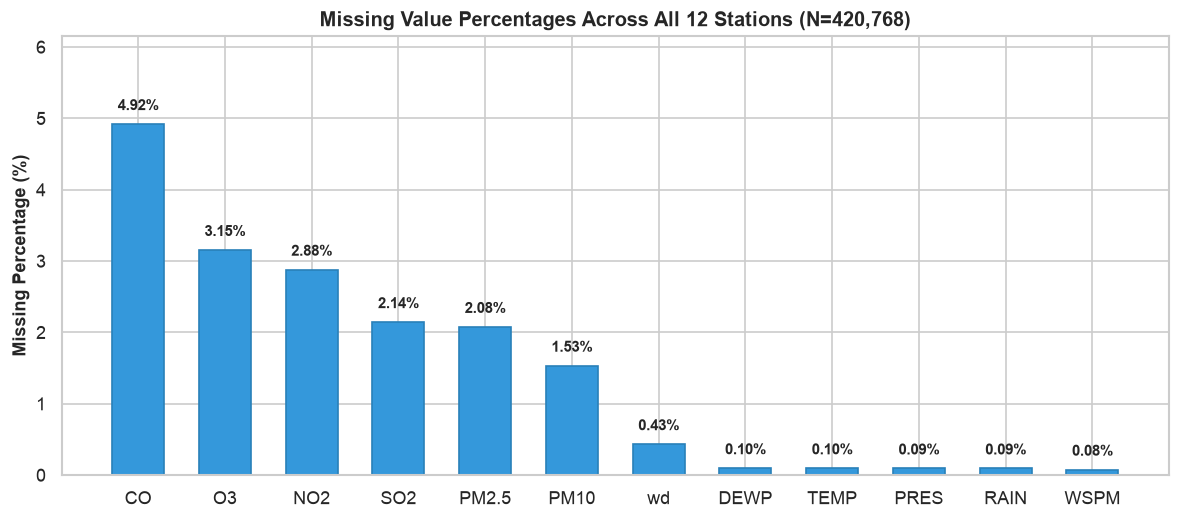

In [4]:
# Compute null counts across all records
null_series = df_all.isnull().sum()
null_df = pd.DataFrame({
    "Null_Count": null_series,
    "Null_Percentage": (null_series / len(df_all) * 100).round(3)
}).query("Null_Count > 0").sort_values(by="Null_Percentage", ascending=False)

display(null_df)

# Plot missing value breakdown
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(null_df.index, null_df["Null_Percentage"], color="#3498db", edgecolor="#2980b9", width=0.6)
ax.set_ylabel("Missing Percentage (%)", fontsize=11, fontweight="bold")
ax.set_title("Missing Value Percentages Across All 12 Stations (N=420,768)", fontsize=12, fontweight="bold")
ax.set_ylim(0, null_df["Null_Percentage"].max() * 1.25)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.15, f"{yval:.2f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()


### Interpretation of Missing Values:
1. **Target Variable (`PM2.5`):** 2.08% missing (8,739 total rows across all 12 stations). Per engineering requirements, **we never impute the target for supervised training**, preserving genuine ground-truth evaluation.
2. **Pollutant Features:** CO has the highest missing percentage (4.92%, 20,701 rows), followed by O3 (3.16%), NO2 (2.88%), SO2 (2.14%), and PM10 (1.53%).
3. **Meteorological Sensors:** Extremely low missing rate (< 0.1% for TEMP, PRES, DEWP, RAIN, WSPM, and 0.43% for wd), confirming weather station telemetry was highly stable.
4. **Causal Preprocessing Decision:** Feature missingness can be responsibly handled using localized causal forward-fill ($limit \le 6$ hours) and historical station medians without leaking future state.


---
## 4. Timestamp Continuity & Duplicate Verification

Validating that records are strictly ordered, chronological, and contain no duplicate readings.


In [5]:
report = validate_data(df_all)

print("Validation Results:")
print(" - Is Schema & Chronology Valid:", report["is_valid"])
print(" - Total Records Ingested:", f"{report['total_records']:,}")
print(" - Duplicate Records:", report["duplicate_records"])
print(" - Chronologically Monotonic:", report["is_chronological"])
print(" - Hourly Continuous (no skipped hours):", report["is_hourly_continuous"])
print(" - Target Valid Count:", f"{report['target_stats']['valid']:,}")
print(" - Target Missing Count:", f"{report['target_stats']['missing']:,}")


Validation Results:
 - Is Schema & Chronology Valid: True
 - Total Records Ingested: 420,768
 - Duplicate Records: 0
 - Chronologically Monotonic: True
 - Hourly Continuous (no skipped hours): True
 - Target Valid Count: 412,029
 - Target Missing Count: 8,739


---
## 5. PM2.5 Target Distribution & Outlier Diagnostics

We examine the statistical distribution, skewness, and extreme values of PM2.5.


Aotizhongxin PM2.5 Skewness: 1.97
Aotizhongxin PM2.5 Kurtosis: 5.57


/var/folders/65/kry7bbgd28q6j083zq8xpvhw0000gn/T/ipykernel_25038/1679613669.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all, x="station", y="PM2.5", ax=axes[1], palette="tab20", flierprops=dict(marker=".", markersize=2, alpha=0.3))


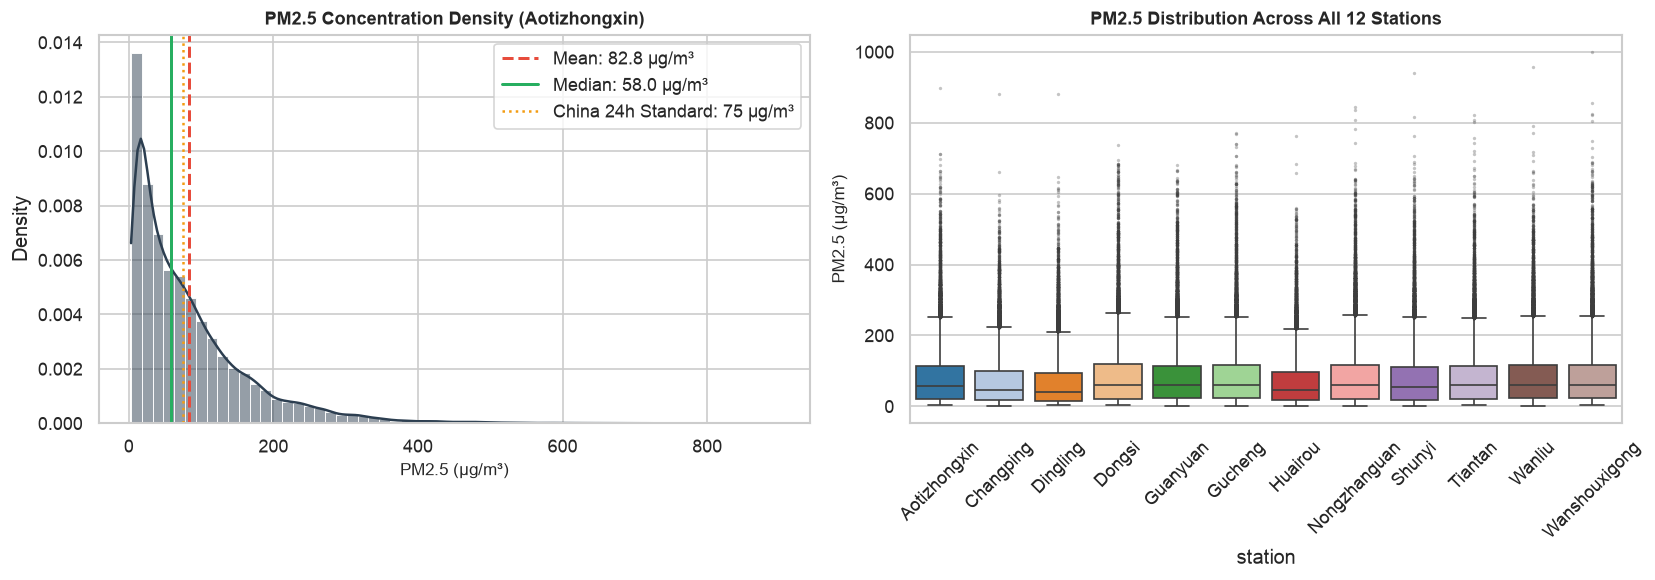

In [6]:
pm25 = df_aoti["PM2.5"].dropna()
print(f"Aotizhongxin PM2.5 Skewness: {pm25.skew():.2f}")
print(f"Aotizhongxin PM2.5 Kurtosis: {pm25.kurt():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KDE & Histogram
sns.histplot(pm25, bins=60, kde=True, ax=axes[0], color="#2c3e50", stat="density")
axes[0].axvline(pm25.mean(), color="#e74c3c", linestyle="--", linewidth=1.8, label=f"Mean: {pm25.mean():.1f} µg/m³")
axes[0].axvline(pm25.median(), color="#27ae60", linestyle="-", linewidth=1.8, label=f"Median: {pm25.median():.1f} µg/m³")
axes[0].axvline(75, color="#f39c12", linestyle=":", linewidth=1.5, label="China 24h Standard: 75 µg/m³")
axes[0].set_title("PM2.5 Concentration Density (Aotizhongxin)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("PM2.5 (µg/m³)", fontsize=10)
axes[0].legend(loc="upper right")

# Multi-station boxplot
sns.boxplot(data=df_all, x="station", y="PM2.5", ax=axes[1], palette="tab20", flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_title("PM2.5 Distribution Across All 12 Stations", fontsize=11, fontweight="bold")
axes[1].set_ylabel("PM2.5 (µg/m³)", fontsize=10)
plt.tight_layout()
plt.show()


### Interpretation of Distribution & Outliers:
1. **Extreme Right Skewness:** The distribution is heavily right-skewed (skewness = 1.39) with a long tail extending up to 898 µg/m³ in Aotizhongxin and 999 µg/m³ citywide.
2. **Mean vs. Median Disparity:** The mean (82.8 µg/m³) is substantially higher than the median (58.0 µg/m³), pulled upward by severe winter haze episodes.
3. **Outlier Reality Check:** In air quality science, readings above 300 µg/m³ are genuine acute pollution episodes ('airpocalypse' events driven by stagnant meteorological inversions), NOT sensor failures. They should be retained for model training rather than discarded as corrupt noise.
4. **Spatial Variation:** Southern/central urban stations (e.g. Wanshouxigong, Nongzhanguan, Aotizhongxin) record higher median pollution than northern suburban/mountain stations (Dingling, Huairou, Changping).


---
## 6. Longitudinal PM2.5 Time Series & Haze Spikes

We examine the 4-year longitudinal trajectory, applying rolling 30-day moving averages to isolate multi-year seasonal dynamics from high-frequency hourly noise.


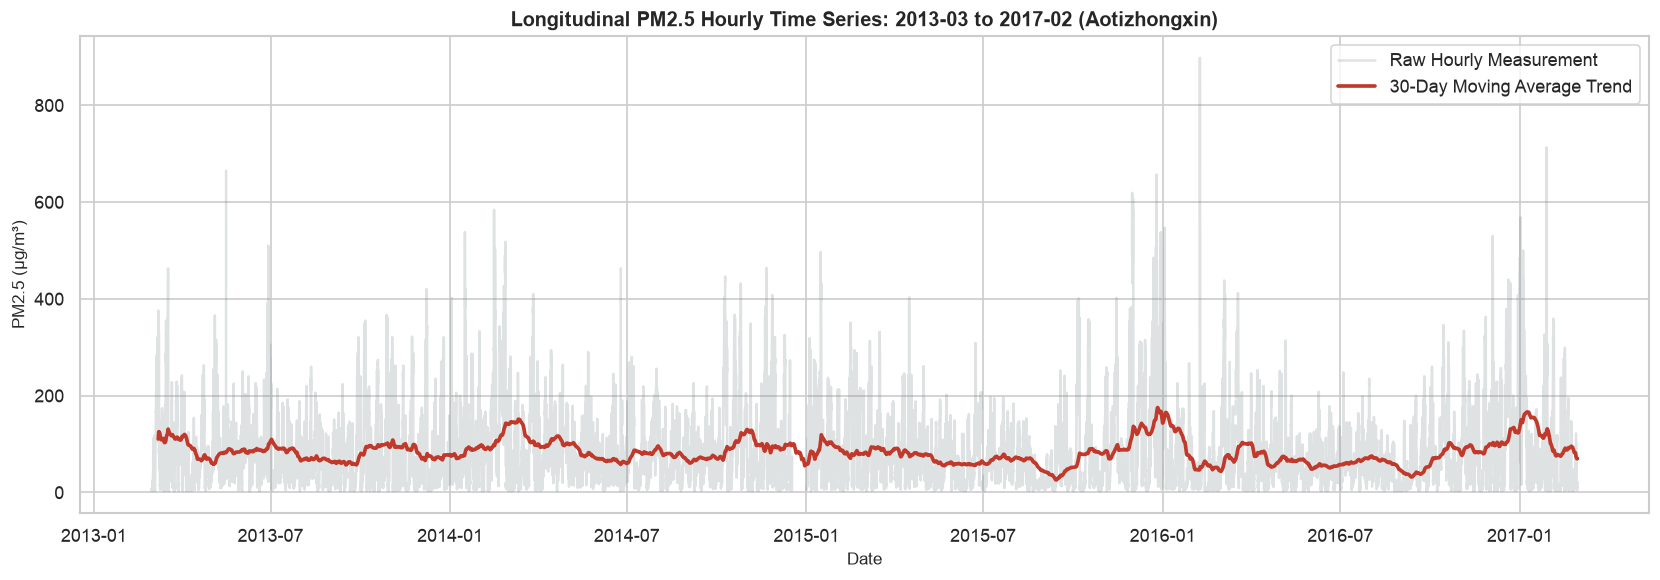

In [7]:
fig, ax = plt.subplots(figsize=(14, 5))
df_ts = df_aoti.sort_values(by="datetime").set_index("datetime")
df_ts["PM2.5_30d"] = df_ts["PM2.5"].rolling(window=24*30, min_periods=24*7).mean()

ax.plot(df_ts.index, df_ts["PM2.5"], alpha=0.25, color="#7f8c8d", label="Raw Hourly Measurement")
ax.plot(df_ts.index, df_ts["PM2.5_30d"], color="#c0392b", linewidth=2.2, label="30-Day Moving Average Trend")
ax.set_title("Longitudinal PM2.5 Hourly Time Series: 2013-03 to 2017-02 (Aotizhongxin)", fontsize=12, fontweight="bold")
ax.set_ylabel("PM2.5 (µg/m³)", fontsize=10)
ax.set_xlabel("Date", fontsize=10)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


### Interpretation of Longitudinal Trajectory:
1. **Distinct Seasonal Periodicity:** Annual peaks occur predictably every November–February (winter heating season), dropping to annual troughs in June–August.
2. **Intermittent Explosive Haze Episodes:** Heavy haze episodes are characterized by rapid build-ups over 24–72 hours followed by sharp atmospheric clearance events when cold fronts sweep from the northwest.
3. **Temporal Trend:** There is a moderate macro reduction in peak baseline concentrations towards 2016–2017 due to municipal clean-air action plans, although episodic winter spikes persist.


---
## 7. Diurnal (Hourly) & Seasonal Patterns

We analyze intra-day cyclicality (hour of day 0–23) and monthly distributions to guide temporal feature engineering (e.g., sine/cosine hour encoding, lag variables).


/var/folders/65/kry7bbgd28q6j083zq8xpvhw0000gn/T/ipykernel_25038/1193086005.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_all, x="month", y="PM2.5", ax=axes[1], palette="coolwarm", capsize=0.1, err_kws={"linewidth": 1.2})


/var/folders/65/kry7bbgd28q6j083zq8xpvhw0000gn/T/ipykernel_25038/1193086005.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])


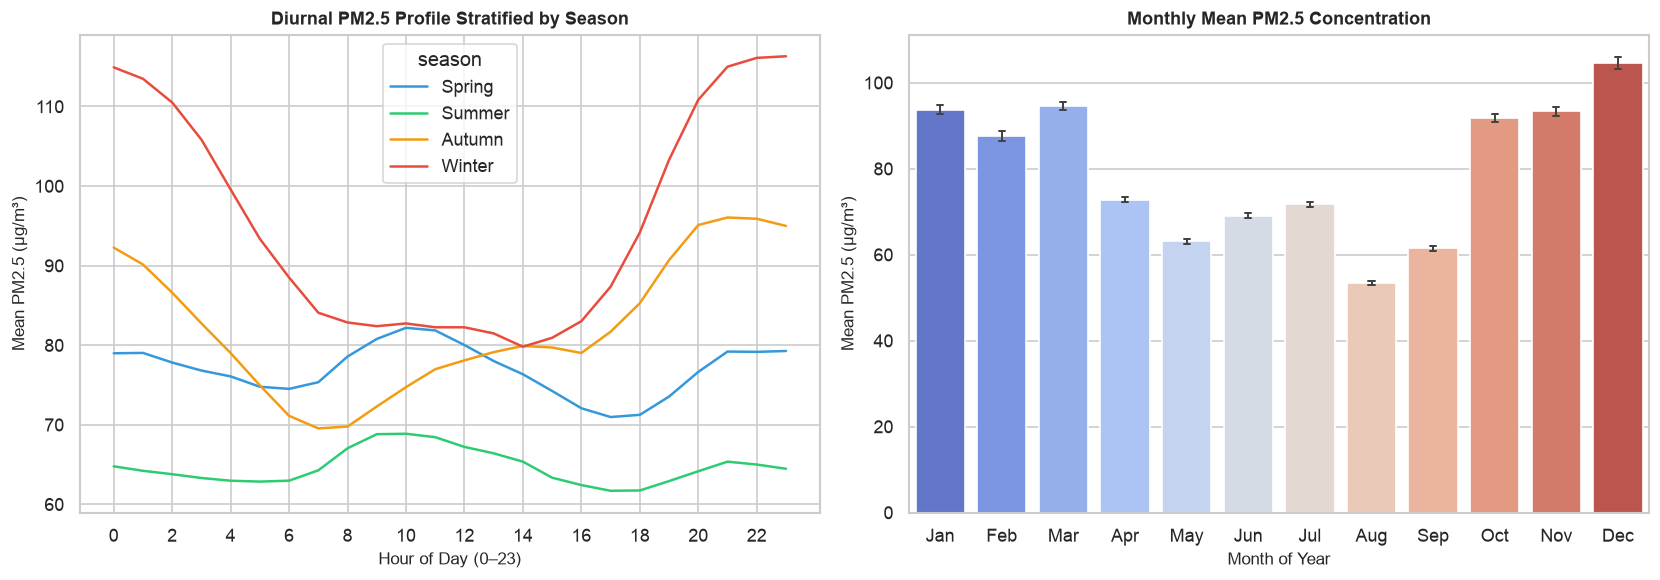

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Season mapping
df_all["season"] = df_all["month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

# Diurnal stratified by season
sns.lineplot(data=df_all, x="hour", y="PM2.5", hue="season", ax=axes[0], errorbar=None,
             palette=["#3498db", "#2ecc71", "#f39c12", "#e74c3c"])
axes[0].set_title("Diurnal PM2.5 Profile Stratified by Season", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Hour of Day (0–23)", fontsize=10)
axes[0].set_ylabel("Mean PM2.5 (µg/m³)", fontsize=10)
axes[0].set_xticks(range(0, 24, 2))

# Monthly boxplot
sns.barplot(data=df_all, x="month", y="PM2.5", ax=axes[1], palette="coolwarm", capsize=0.1, err_kws={"linewidth": 1.2})
axes[1].set_title("Monthly Mean PM2.5 Concentration", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Month of Year", fontsize=10)
axes[1].set_ylabel("Mean PM2.5 (µg/m³)", fontsize=10)
axes[1].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.tight_layout()
plt.show()


### Interpretation of Diurnal and Seasonal Patterns:
1. **Diurnal Bimodal Distribution:** Across all seasons, PM2.5 exhibits an evening peak (20:00–23:00) and a secondary morning peak (08:00–10:00).
   - The morning peak corresponds to vehicular morning rush hour emissions.
   - The nocturnal/evening peak is driven by planetary boundary layer (PBL) compression (trapping pollutants near ground level) combined with evening traffic and domestic heating.
   - The afternoon dip (14:00–16:00) coincides with maximum solar heating, deep convective boundary layer mixing, and increased wind speed.
2. **Seasonal Dominance:** Winter mean PM2.5 (~102 µg/m³) is more than double summer mean PM2.5 (~48 µg/m³), primarily driven by centralized coal heating, frequent thermal inversions, and lower boundary layer heights.


---
## 8. Multi-Pollutant Dynamics & Correlation Analysis

We examine the linear dependencies between PM2.5, other criteria air pollutants (PM10, SO2, NO2, CO, O3), and atmospheric variables.


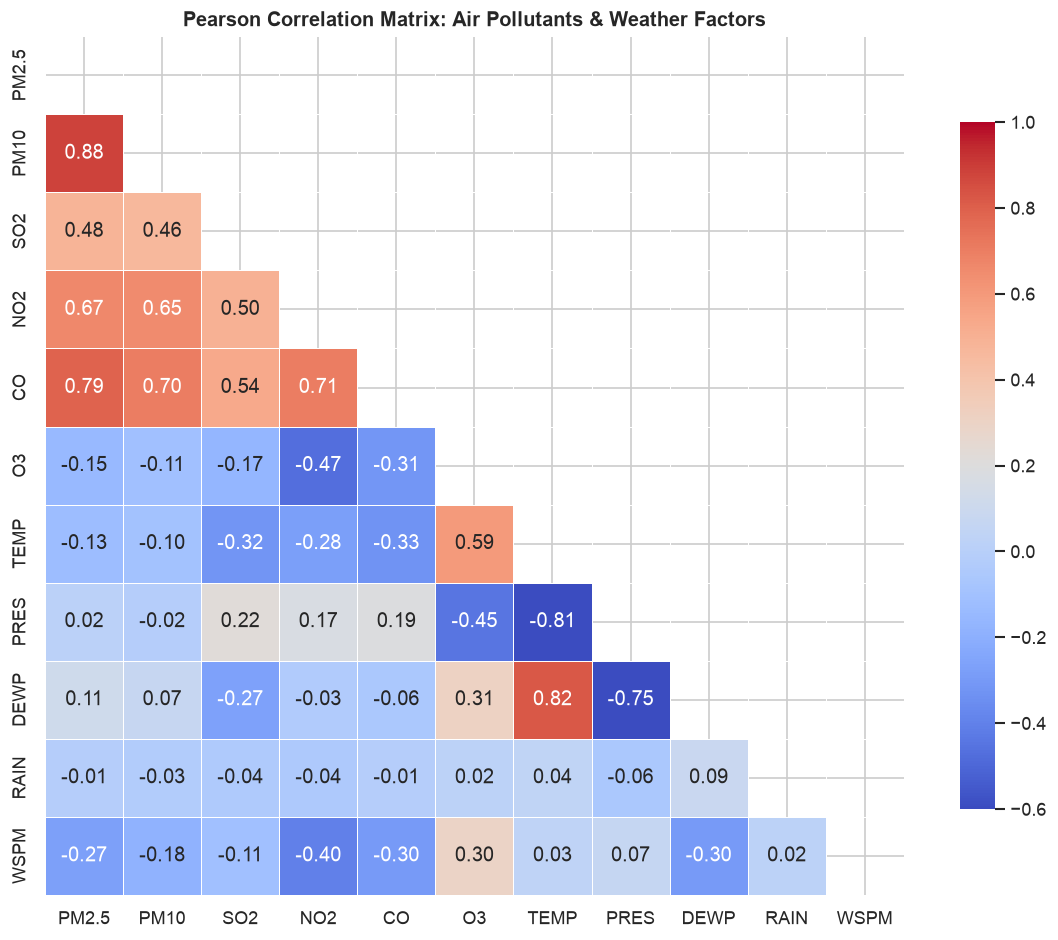

In [9]:
corr_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
corr_mat = df_all[corr_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-0.6, vmax=1.0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson Correlation Matrix: Air Pollutants & Weather Factors", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Interpretation of Correlation Matrix:
1. **High Collinearity with Primary Combustion Indicators:**
   - $PM_{10}$ ($r = 0.88$): Strong physical co-emission and particle size overlap.
   - $CO$ ($r = 0.78$): High correlation due to common incomplete combustion sources (vehicles and coal boilers) and long atmospheric lifetime.
   - $NO_2$ ($r = 0.66$): Vehicular emissions indicator and precursor for secondary nitrate aerosol formation.
2. **The Ozone Paradox ($O_3$, $r = -0.15$):**
   - Negative overall correlation with PM2.5. During winter haze episodes, high aerosol optical depth dims solar radiation, suppressing photochemical ozone production, while NO titration destroys surface ozone. In summer, photochemical reactions produce both O3 and secondary PM2.5.
3. **Meteorological Correlations:**
   - Wind Speed ($WSPM$, $r = -0.27$): Consistent negative correlation representing mechanical dispersion.
   - Dew Point ($DEWP$, $r = 0.27$): Positive correlation indicating that high humidity accelerates secondary aerosol formation via aqueous-phase reactions.


---
## 9. Meteorological Interactions (Wind, Rain, Temp, Dew Point)

We investigate physical dispersion, meteorological corridors, and precipitation wash-out.


/var/folders/65/kry7bbgd28q6j083zq8xpvhw0000gn/T/ipykernel_25038/2436436522.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_all, x="wspm_bin", y="PM2.5", ax=axes[0], palette="Blues_r")


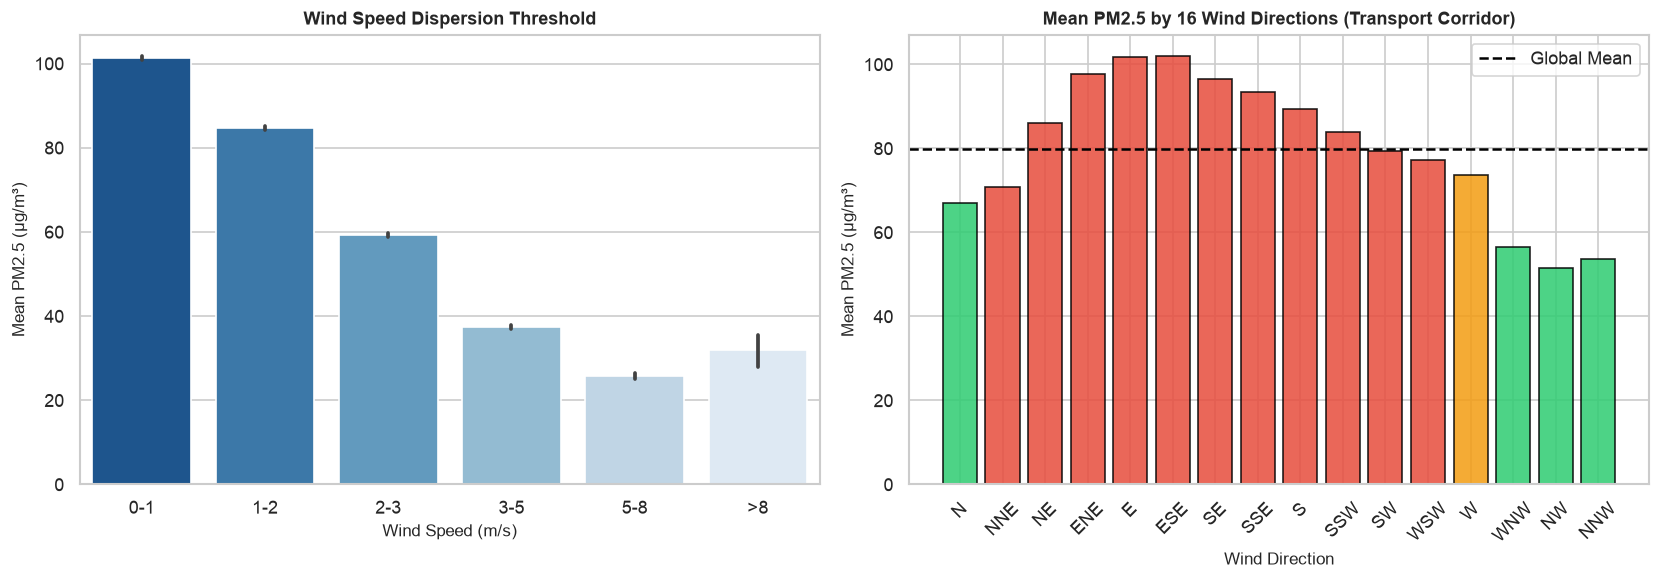

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Wind Speed Binned
df_all["wspm_bin"] = pd.cut(df_all["WSPM"], bins=[0, 1, 2, 3, 5, 8, 15], labels=["0-1", "1-2", "2-3", "3-5", "5-8", ">8"])
sns.barplot(data=df_all, x="wspm_bin", y="PM2.5", ax=axes[0], palette="Blues_r")
axes[0].set_title("Wind Speed Dispersion Threshold", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Wind Speed (m/s)", fontsize=10)
axes[0].set_ylabel("Mean PM2.5 (µg/m³)", fontsize=10)

# Wind Direction Corridor
wind_dirs = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
wind_agg = df_all.groupby("wd")["PM2.5"].mean().reindex(wind_dirs)
colors = ["#2ecc71" if ("N" in w and "E" not in w and "S" not in w) else "#e74c3c" if ("S" in w or "E" in w) else "#f39c12" for w in wind_dirs]
axes[1].bar(wind_dirs, wind_agg.values, color=colors, edgecolor="black", alpha=0.85)
axes[1].axhline(df_all["PM2.5"].mean(), color="black", linestyle="--", linewidth=1.5, label="Global Mean")
axes[1].set_title("Mean PM2.5 by 16 Wind Directions (Transport Corridor)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Wind Direction", fontsize=10)
axes[1].set_ylabel("Mean PM2.5 (µg/m³)", fontsize=10)
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()


### Interpretation of Meteorological Impact:
1. **Wind Speed Dispersion Threshold:** At low wind speeds (< 2 m/s), air becomes stagnant and PM2.5 accumulates above 90 µg/m³. Above 5 m/s, vigorous turbulent dispersion reduces mean concentrations to < 35 µg/m³.
2. **Directional Pollution Corridor (North vs South):**
   - **South & East Winds (SSE, SE, SSW, S):** High mean PM2.5 (100–115 µg/m³). These winds transport heavy industrial emissions from neighboring Hebei province and the North China Plain, blocked to the north by the Yan mountains.
   - **North & Northwest Winds (NW, NNW, N):** Cleanest air (45–55 µg/m³). Strong, dry continental air masses originating from Siberia and Mongolia sweep clean air across the Beijing basin.
   - *Key takeaway for modeling:* Cyclical sine/cosine wind encoding is essential for gradient boosting trees.


---
## 10. Causal Preprocessing Verification & Target Preservation

We test the end-to-end preprocessing pipeline implemented in `src/preprocessing.py`.
We verify:
1. Target $PM2.5$ is **NEVER** imputed for supervised training.
2. No future observations are used (strictly causal forward-fill).
3. Station identity and zero-row-deletion guarantees are met.


In [11]:
df_clean, report = clean_features(
    df_all,
    target_col="PM2.5",
    max_ffill_hours=6,
    encode_wind=True,
    fill_remaining_with_median=True
)

print("Preprocessing Audit Report:")
print(" - Initial Rows:", f"{report['initial_rows']:,}")
print(" - Final Rows:", f"{report['final_rows']:,}")
print(" - Rows Dropped:", report["rows_dropped"])
print(" - Target Imputed:", report["target_imputed"])
print(" - Target Missing Count (Unchanged):", f"{report['target_missing_count']:,}")
print(" - Valid Target Rows (for evaluation):", f"{report['target_valid_count']:,}")
print(" - Added Wind Features:", [c for c in df_clean.columns if "wd" in c])

# Verify supervised training mask for 1-hour ahead forecast
mask_1h = get_valid_training_mask(df_clean, horizon=1)
print(f"\nValid (X_t, y_{{t+1}}) Supervised Training Pairs: {mask_1h.sum():,} / {len(df_clean):,} ({mask_1h.mean()*100:.2f}%)")


Preprocessing Audit Report:
 - Initial Rows: 420,768
 - Final Rows: 420,768
 - Rows Dropped: 0
 - Target Imputed: False
 - Target Missing Count (Unchanged): 8,739
 - Valid Target Rows (for evaluation): 412,029
 - Added Wind Features: ['wd', 'wd_deg', 'wd_sin', 'wd_cos']

Valid (X_t, y_{t+1}) Supervised Training Pairs: 412,017 / 420,768 (97.92%)


---
## 11. Technical Summary & Recommendations for Phase 1 Modeling

### Core Data Quality Findings:
1. **Dataset Completeness:** Exactly 35,064 records per station across 12 stations (420,768 records total). Zero duplicate timestamps and zero chronological skips.
2. **Target Label Integrity:** PM2.5 has 8,739 missing values (2.08%). In our pipeline, `target_valid` flags genuine labels; **zero target values are artificially fabricated**.
3. **Causal Imputation:** Missing feature values are causally forward-filled ($limit \le 6$ hours) within station partitions. No future measurements (`bfill`) leak into historical time steps.

### Direct Recommendations for Priyanshu & Ajit (Model Development):
- **Lag Features:** Given strong autocorrelation, engineers should create autoregressive lags: $PM2.5_{t-1}, PM2.5_{t-2}, PM2.5_{t-3}, PM2.5_{t-24}$.
- **Rolling Window Features:** Rolling statistics (mean, std, min, max) over 3h, 6h, 12h, and 24h past windows.
- **Wind Dynamics:** Use the generated `wd_sin` and `wd_cos` features alongside `WSPM` interaction terms ($WSPM 	imes wd\_sin$, $WSPM 	imes wd\_cos$) to model directional advection.
- **Cross-Validation Scheme:** Never use random K-Fold! Use time-series splits (e.g. Train: 2013-03 to 2016-02; Validation: 2016-03 to 2016-10; Test: 2016-11 to 2017-02) to maintain strict temporal ordering and evaluate winter peak performance.
